In [1]:
import torch

if torch.cuda.is_available():
  print("Success! GPU is active and ready to process video.")
else:
  print("Uh oh. The GPU is not active. Check Step 2 again.")

Success! GPU is active and ready to process video.


In [1]:
import os

# 1. Inject your Kaggle credentials directly into the environment
os.environ['KAGGLE_USERNAME'] = 'syedabdulnafay'
os.environ['KAGGLE_KEY'] = 'KGAT_686c77c7b152ac7aa0adfcb70eae1696'

# 2. Install the Kaggle library quietly (-q)
!pip install -q kaggle

# 3. Download the SCVD dataset directly from Kaggle's servers
print('Downloading SCVD dataset...')
!kaggle datasets download -d toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd

# 4. Unzip the downloaded file into a new folder called 'scvd_dataset'
print('Unzipping dataset... this might take a minute...')
!unzip -q smartcity-cctv-violence-detection-dataset-scvd.zip -d scvd_dataset

print('Success! Data acquired.')

Dataset URL: https://www.kaggle.com/datasets/toluwaniaremu/smartcity-cctv-violence-detection-dataset-scvd
License(s): CC-BY-NC-SA-4.0
100% 1.03G/1.03G [00:08<00:00, 135MB/s]

Unzipping dataset... this might take a minute...
Success! Data acquired.


In [3]:
!pip install -q av

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 50.7 MB/s eta 0:00:00


In [4]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.io import read_video

class SchoolBullyingDataset(Dataset):
  def __init__(self, root_dir):
    self.video_paths = []
    self.labels = []

    # We group 'Violence' and 'Weaponized' together as a single "Violent" class (Label 1)
    class_mapping = {'Normal': 0, 'Violence': 1, 'Weaponzied': 1}

    print(f"Scanning folder: {root_dir}")
    for class_name, label in class_mapping.items():
      class_dir = os.path.join(root_dir, class_name)

      # If the folder exists, look inside it
      if os.path.exists(class_dir):
        for file in os.listdir(class_dir):
          if file.endswith('.avi'):
            self.video_paths.append(os.path.join(class_dir, file))
            self.labels.append(label)

    print(f"Found {len(self.video_paths)} videos for training!")

  def __len__(self):
    # Tells Pytorch exactly how many videos we have
    return len(self.video_paths)

  def __getitem__(self, idx):
    # This is the core engine. Pytorch calls this function to grab ONE video at a time.
    video_path = self.video_paths[idx]
    label = self.labels[idx]

    # 1. READ THE VIDEO
    # Grabs the video and formats it as (Time, Channels, Height, Width)
    vframes, aframes, info = read_video(video_path, pts_unit='sec', output_format="TCHW")

    # 2. STANDARDIZE THE TIME (Exactly 16 frames)
    if vframes.shape[0] >= 16:
      vframes = vframes[:16] # If the video is long, just take the first 16 frames
    else:
      # If the video is too short, duplicate the last frame to fill the gap up to 16
      padding = vframes[-1:].repeat(16 - vframes.shape[0], 1, 1, 1)
      vframes = torch.cat((vframes, padding), dim=0)

    # 3. STANDARDIZE THE SHAPE & COLOR
    # Resize to 112x112 pixels (What the 3D ResNet expects)
    resize = T.Resize((112, 112), antialias=True)
    vframes = resize(vframes)

    # Convert pixel colors from 0-255 down to 0.0-1.0 (Models prefer tiny decimals)
    vframes = vframes / 255.0

    # 4. REARRANGE FOR THE MODEL
    # Pytorch 3D models specifically want the order to be: (Channels, Time, Height, Width)
    # We use .permute() to swap Time and Channels dimensions
    vframes = vframes.permute(1, 0, 2, 3)

    return vframes, torch.tensor(label, dtype=torch.long)

In [5]:
# Point the script to your training data
# Note: Google Colab usually puts everything inside a folder called '/content'
train_folder_path = '/content/scvd_dataset/SCVD/SCVD_converted_sec_split/Train'

# Create the dataset
my_training_data = SchoolBullyingDataset(train_folder_path)

# Let's pull out the very first video (Index 0) and see what it looks like in math form
first_video_tensor, first_video_label = my_training_data[0]

print('---')
print(f'Label: {first_video_label} (0=Normal, 1=Violent)')
print(f'Tensor Shape: {first_video_tensor.shape}')
print('If the shape says [3, 16, 112, 112], your data pipeline is absolutely perfect!')

Scanning folder: /content/scvd_dataset/SCVD/SCVD_converted_sec_split/Train
Found 1842 videos for training!


/usr/local/lib/python3.12/dist-packages/torchvision/io/_video_deprecation_warning.py:9: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


---
Label: 0 (0=Normal, 1=Violent)
Tensor Shape: torch.Size([3, 16, 112, 112])
If the shape says [3, 16, 112, 112], your data pipeline is absolutely perfect!


In [6]:
!pip install av

In [7]:
import torch
import torch.nn as nn
import torchvision.models.video as video_models

print("Downloading the pre-trained R3D_18 model (This might take a few seconds)...")

# 1. LOAD THE PRE-TRAINED MODEL
# We pull the model and its pre-learned Kinetics-400 weights
weights = video_models.R3D_18_Weights.DEFAULT
model = video_models.r3d_18(weights=weights)

# 2. FREEZE THE KNOWLEDGE (Transfer Learning)
# We loop through all the existing "neurons" and tell PyTorch NOT to update them.
# This saves massive computing power and prevents the model from forgetting the basics.
for param in model.parameters():
  param.requires_grad = False

# 3. THE SURGERY (Replacing the Head)
# We find out how many connections are flowing into the final layer
num_features = model.fc.in_features

# We replace the old 400-class layer with a new 2-class layer (0: Normal, 1: Violent)
model.fc = nn.Linear(num_features, 2)

# We make sure the this brand new layer is unlocked and ready to learn
for param in model.fc.parameters():
  param.requires_grad = True

# 4. MOVE TO THE SUPERCOMPUTER
# We tell PyTorch to grab our newly modified model and throw it onto the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("\n--- Surgery Complete ---")
print(f"Model successfully moved to: {device}")
print("If the device above says 'cuda', your GPU is active and the brain is ready!")

Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 161MB/s]



--- Surgery Complete ---
Model successfully moved to: cuda
If the device above says 'cuda', your GPU is active and the brain is ready!


In [9]:
import torch.optim as optim
from torch.utils.data import DataLoader

print("Setting up the classroom...")

# 1. BATCHING (The DataLoader)
# Video tensors are massive. If we try to feed all our videos to the GPU at once,
# it will instantly crash (Out of Memory error). We group them into tiny batches of 4.
batch_size = 4
train_loader = DataLoader(my_training_data, batch_size=batch_size, shuffle=True)

# 2. THE GRADER & THE STUDENT
# CrossEntropyLoss is the standard mathematical formula for grading multiple-choice questions
criterion = nn.CrossEntropyLoss()

# The Optimizer is the student. It updates the weights based on the Grader's feedback.
# We explicitly tell it to ONLY update our newly added final layer (model.fc)
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# 3. THE LOOP
# An "Epoch" is one complete read-through of the entire training textbook (dataset)
epochs = 5

print("Starting the Training Loop! Grab a coffee, this will take a few minutes...")

for epoch in range(epochs):
  model.train() # Set the model to "Learning Mode"
  running_loss = 0.0

  # We loop through our dataset, grabbing 4 videos (inputs) and 4 answers (labels) at a time
  for i, (inputs, labels) in enumerate(train_loader):

    # Move the data from the CPU's RAM onto the GPU's ultra-fast memory
    inputs = inputs.to(device)
    labels = labels.to(device)

    # Step A: Wipe the slate clean
    # PyTorch accumulates gradients (learning signals) by default. We must reset them per batch.
    optimizer.zero_grad()

    # Step B: The Forward Pass (Make a guess)
    outputs = model(inputs)

    # Step C: Calculate the Error (How wrong was the guess?)
    loss = criterion(outputs, labels)

    # Step D: The Backward Pass (Learn from the mistake)
    # This calculates exactly how much to adjust the math in the final layer
    loss.backward()

    # Apply the adjustments
    optimizer.step()

    running_loss += loss.item()

    # Print a progress update every 10 batches so we know it hasn't frozen
    if (i + 1) % 10 == 0:
      print(f"Epoch [{epoch+1}/{epochs}], Batch [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

  # Print the average error at the end of the every epoch.
  # We want to see the number go DOWN over time!
  epoch_loss = running_loss / len(train_loader)
  print(f"--- End of Epoch {epoch + 1} | Average Loss: {epoch_loss:.4f} ---")

print("\n Training Complete! The brain has been successfully educated")

Setting up the classroom...
Starting the Training Loop! Grab a coffee, this will take a few minutes...


/usr/local/lib/python3.12/dist-packages/torchvision/io/_video_deprecation_warning.py:9: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


Epoch [1/5], Batch [10/461], Loss: 0.6715
Epoch [1/5], Batch [20/461], Loss: 0.5770
Epoch [1/5], Batch [30/461], Loss: 0.5997
Epoch [1/5], Batch [40/461], Loss: 0.5795
Epoch [1/5], Batch [50/461], Loss: 0.6089
Epoch [1/5], Batch [60/461], Loss: 0.9703
Epoch [1/5], Batch [70/461], Loss: 0.8103
Epoch [1/5], Batch [80/461], Loss: 0.5308
Epoch [1/5], Batch [90/461], Loss: 0.7274
Epoch [1/5], Batch [100/461], Loss: 0.3437
Epoch [1/5], Batch [110/461], Loss: 0.5351
Epoch [1/5], Batch [120/461], Loss: 0.5396
Epoch [1/5], Batch [130/461], Loss: 0.7364
Epoch [1/5], Batch [140/461], Loss: 0.6485
Epoch [1/5], Batch [150/461], Loss: 0.6233
Epoch [1/5], Batch [160/461], Loss: 0.4611
Epoch [1/5], Batch [170/461], Loss: 0.2946
Epoch [1/5], Batch [180/461], Loss: 0.7056
Epoch [1/5], Batch [190/461], Loss: 0.5114
Epoch [1/5], Batch [200/461], Loss: 0.4689
Epoch [1/5], Batch [210/461], Loss: 0.4526
Epoch [1/5], Batch [220/461], Loss: 0.7756
Epoch [1/5], Batch [230/461], Loss: 0.4748
Epoch [1/5], Batch [

In [16]:
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.io import read_video

def analyze_cctv_feed(video_path, threshold=0.60):
  """
  Simulates a real-time CCTV feed analysis.
  If the probability of violence > threshold (60%), it triggers an alert.
  """
  print(f"\n[SYSTEM] Analyzing feed: {video_path.split('/')[-1]}...")

  # 1. SET TEST VIDEO
  # Turns off learning mode so that the model's brain doesn't accidentally change.
  model.eval()

  # 2. PROCESS THE INCOMING VIDEO (Same rules as Phase 2)
  try:
    vframes, _, _ = read_video(video_path, pts_unit='sec', output_format="TCHW")
  except Exception as e:
    print("[ERROR] Could not read video file")
    return

  # Trim or pad to 16 frames
  if vframes.shape[0] >= 16:
    vframes = vframes[:16]
  else:
    padding = vframes[-1].repeat(16 - vframes.shape[0], 1, 1, 1)
    vframes = torch.cat((vframes, padding), dim=0)

  # Resize and normalize
  resize = T.Resize((112, 112), antialias=True)
  vframes = resize(vframes) / 255.0
  vframes = vframes.permute(1, 0, 2, 3)

  # Add a "batch" dimension because the model always expects batches (even if it's just one video)
  # Shape becomes [1, 3, 16, 112, 112]
  inputs = vframes.unsqueeze(0).to(device)

  # 3. MAKE THE PREDICTION
  with torch.no_grad(): # Tells Python to save memory, we aren't training right now
    outputs = model(inputs)

    # Convert the raw output math into a percentage (0.0 to 1.0)
    probabilities = F.softmax(outputs, dim=1)

    # Get the probability of Class 1 (Violence)
    violence_prob = probabilities[0][1].item()

  # 4. THE MANAGEMENT ALERT LOGIC
  print(f"[AI CONFIDENCE] Violence Probability: {violence_prob * 100:.2f}%")

  if violence_prob >= threshold:
    print("🚨🚨 [ALERT TRIGGERED] 🚨🚨")
    print("PHYSICAL ALTERCATION DETECTED! NOTIFYING SCHOOL MANAGEMENT IMMEDIATELY.")
  else:
    print("✅ [STATUS NORMAL] No violent behavior detected.")

print("Alert system online and ready for testing.")

Alert system online and ready for testing.


In [24]:
# Replace the string below with the path you just copied!
analyze_cctv_feed('/content/scvd_dataset/SCVD/SCVD_converted_sec_split/Test/Normal/Normal-Test092.avi')


[SYSTEM] Analyzing feed: Normal-Test092.avi...
[AI CONFIDENCE] Violence Probability: 3.11%
✅ [STATUS NORMAL] No violent behavior detected.


In [25]:
from google.colab import files

# 1. Define the filename for your saved brain
model_filename = 'safespace_bullying_model.pth'

# 2. Extract the learned weights (state_dict) and save them as a file
print(f"Saving model weights to {model_filename}...")
torch.save(model.state_dict(), model_filename)

# 3. Download the file from the cloud directly to your local computer
print("Downloading to your computer... check your browser downloads!")
files.download(model_filename)

Saving model weights to safespace_bullying_model.pth...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
!pip install -q scikit-learn seaborn matplotlib

Setting up the Evaluation Engine...
Scanning folder: /content/scvd_dataset/SCVD/SCVD_converted_sec_split/Test
Found 287 videos for training!

Evaluating 287 unseen videos. This will take a few minutes...


/usr/local/lib/python3.12/dist-packages/torchvision/io/_video_deprecation_warning.py:9: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


Processed 36 videos...
Processed 76 videos...
Processed 116 videos...
Processed 156 videos...
Processed 196 videos...
Processed 236 videos...
Processed 276 videos...

     OFFICIAL PERFORMANCE REPORT
              precision    recall  f1-score   support

  Normal (0)       0.98      0.99      0.99       169
 Violent (1)       0.98      0.97      0.98       118

    accuracy                           0.98       287
   macro avg       0.98      0.98      0.98       287
weighted avg       0.98      0.98      0.98       287



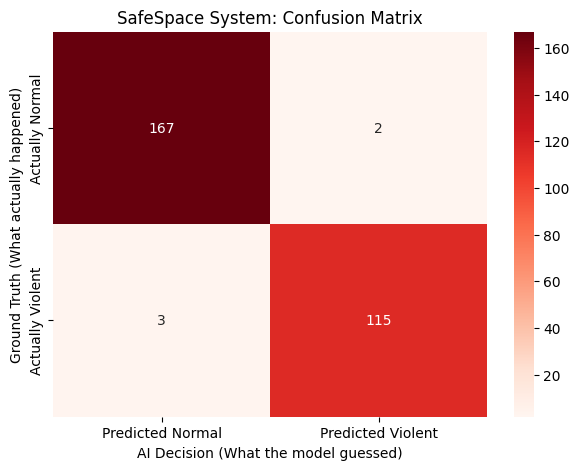

In [27]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader

print("Setting up the Evaluation Engine...")

# 1. Locate the Test Data
test_folder_path = '/content/scvd_dataset/SCVD/SCVD_converted_sec_split/Test'

# 2. Create the Dataset and DataLoader
# We use the SchoolBullyingDataset class we built in Phase 2
test_data = SchoolBullyingDataset(test_folder_path)

# shuffle=False is important here. We want to test them in a straight line.
test_loader = DataLoader(test_data, batch_size=4, shuffle=False)

# 3. Storage for our results
all_predictions = []
all_true_labels = []

# 4. Lock the Brain
model.eval() # Strictly testing mode, no learning!

print(f"\nEvaluating {len(test_data)} unseen videos. This will take a few minutes...")

# 5. The Evaluation Loop
with torch.no_grad(): # Tells the GPU not to waste memory tracking gradients
    for i, (inputs, labels) in enumerate(test_loader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        # The model makes its guesses
        outputs = model(inputs)

        # We grab the highest probability (Is it leaning towards 0 or 1?)
        _, predicted = torch.max(outputs, 1)

        # Move the results off the GPU and save them to our lists
        all_predictions.extend(predicted.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

        # Print a tiny update so you know it hasn't frozen
        if (i + 1) % 10 == 0:
            print(f"Processed {i * 4} videos...")

# 6. Generate the Mathematical Report
print("\n" + "="*40)
print("     OFFICIAL PERFORMANCE REPORT")
print("="*40)
target_names = ['Normal (0)', 'Violent (1)']
print(classification_report(all_true_labels, all_predictions, target_names=target_names))

# 7. Draw the Confusion Matrix Map
cm = confusion_matrix(all_true_labels, all_predictions)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Normal', 'Predicted Violent'],
            yticklabels=['Actually Normal', 'Actually Violent'])
plt.ylabel('Ground Truth (What actually happened)')
plt.xlabel('AI Decision (What the model guessed)')
plt.title('SafeSpace System: Confusion Matrix')
plt.show()